# 11 · Model predictive control of a smart home: battery, PV and EV under uncertainty
**Level 4 · Decision support under uncertainty** &nbsp;|&nbsp; Course link: *Module 3 – decision support: optimisation with
forecasts, model predictive control, stochastic and robust programming*

Notebook 09 assumed a perfect forecast. Real controllers must decide **now** with **imperfect forecasts**. Model
predictive control (MPC) solves this with a *receding horizon*:
1. forecast the next 24 h (load, PV, prices);
2. optimise the schedule for those 24 h;
3. apply **only the first hour**, measure what really happened;
4. move one hour forward and repeat.

Feedback corrects forecast errors continuously. We then make the optimisation itself uncertainty-aware: **stochastic MPC**
(minimise the *expected* cost over scenarios) and **robust MPC** (minimise the *worst-case* cost).

**The home:** 4 500 kWh/yr household (SimBench H0 profile), 8 kWp PV, 10 kWh / 5 kW battery, an electric car that
plugs in on weekday evenings (18:00 to 07:00) and needs 12 kWh. Dynamic tariff = German day-ahead price + 0.25 €/kWh
fees; feed-in pays 0.08 €/kWh; a capacity tariff charges 0.50 €/kWh for imports above 7 kW.

The optimisation is written in **matrix form** with `scipy.optimize.linprog(c, A_ub, b_ub, A_eq, b_eq, bounds)`:
the same argument order as MATLAB `linprog(f, A, b, Aeq, beq, lb, ub)`.

In [1]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.optimize import linprog
from energy_ai import home_profiles, style
style()

## 1. One year of data
SimBench gives 15-min household and PV profiles (rotated so weekdays match 2019); prices are the real 2019 DE-LU
day-ahead prices converted to local time.

household 4500 kWh/yr, peak 3.7 kW | PV 5405 kWh/yr | 260 EV sessions | price -90 to 121 €/MWh


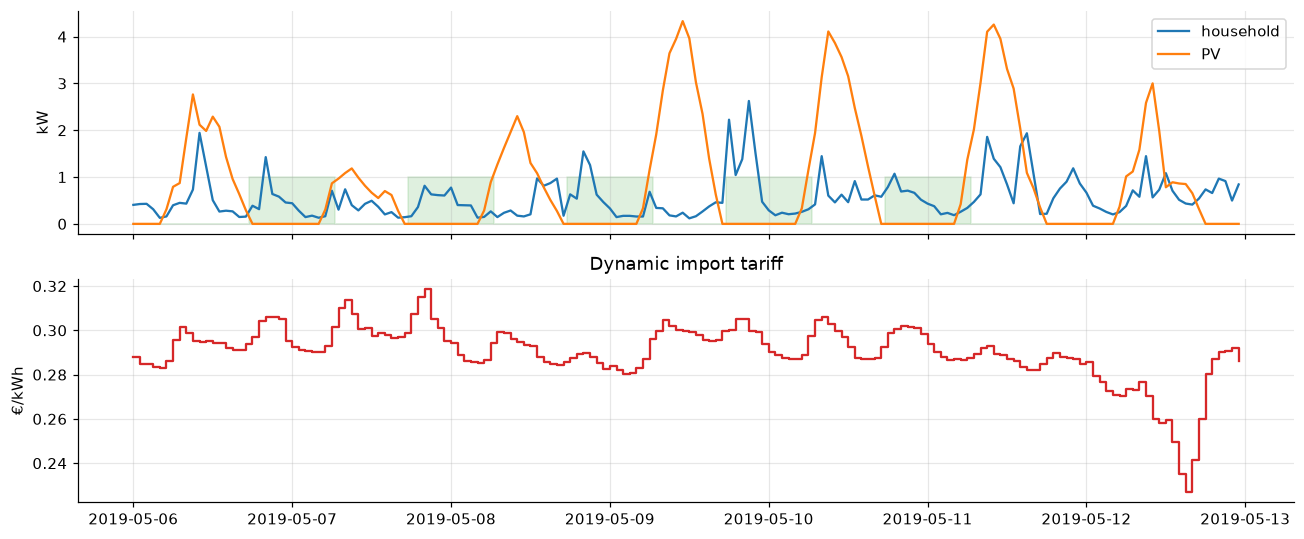

In [2]:
home_df = home_profiles(household="H0-B", annual_kwh=4500, pv_kwp=8.0, fees_eur_kwh=0.25)
hours = home_df.index
load, pv, price, buy = (home_df[c].values for c in ("load_kw", "pv_kw", "price_eur_mwh", "buy_eur_kwh"))

E, PB, ETA, EMIN = 10.0, 5.0, 0.95, 1.0                # battery kWh, kW, one-way efficiency, min SoC
PEV, EV_KWH = 11.0, 12.0                              # charger kW, energy needed per weekday session
PLIM, PEN, SELL, WEAR = 7.0, 0.50, 0.08, 0.01         # capacity limit kW, penalty €/kWh, feed-in €/kWh, wear €/kWh
H = 24                                                # MPC horizon [h]

home = np.zeros(len(hours), bool); sessions = []
for day in pd.date_range("2019-01-01", "2019-12-30"):
    if day.dayofweek < 5:
        a = hours.get_loc(day + pd.Timedelta(hours=18)); dep = a + 13
        home[a:dep] = True; sessions.append((a, dep))
print(f"household {load.sum():.0f} kWh/yr, peak {load.max():.1f} kW | PV {pv.sum():.0f} kWh/yr | {len(sessions)} EV sessions | "
      f"price {price.min():.0f} to {price.max():.0f} €/MWh")

SIM = slice(hours.get_loc(pd.Timestamp("2019-05-06")), hours.get_loc(pd.Timestamp("2019-05-27")))   # 3 weeks
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
w = slice(SIM.start, SIM.start + 7 * 24)
ax[0].plot(hours[w], load[w], label="household"); ax[0].plot(hours[w], pv[w], label="PV"); ax[0].set(ylabel="kW"); ax[0].legend()
ax[0].fill_between(hours[w], 0, home[w] * 1.0, color="tab:green", alpha=0.15, step="mid", label="EV plugged in")
ax[1].step(hours[w], buy[w], where="post", color="tab:red"); ax[1].set(ylabel="€/kWh", title="Dynamic import tariff")
plt.tight_layout(); plt.show()

## 2. Forecasts and their errors
A simple, honest forecaster: household load = mean of the same hour over the last 7 days; PV = mean of the same hour
over the last 3 days. Prices are known a day ahead (day-ahead market).
The **errors of the past 28 days** form a library of realistic error trajectories, used to build scenarios.

In [3]:
def forecast(t, n=H):
    k = np.arange(t, t + n)
    fl = np.mean([load[k - 24 * d] for d in range(1, 8)], axis=0)
    fp = np.mean([pv[k - 24 * d] for d in range(1, 4)], axis=0)
    return fl, fp

err_load, err_pv = np.zeros(len(hours)), np.zeros(len(hours))
for t in range(SIM.start - 30 * 24, SIM.stop + H):
    fl, fp = forecast(t, 1); err_load[t], err_pv[t] = load[t] - fl[0], pv[t] - fp[0]
past = np.arange(SIM.start - 28 * 24, SIM.start)
print(f"forecast MAE over the 28 training days: load {np.abs(err_load[past]).mean():.2f} kW, PV {np.abs(err_pv[past]).mean():.2f} kW")

def scenarios(t, S, rng):
    """S scenarios of (load - PV) for the next H hours = forecast + an error trajectory of a random past day."""
    fl, fp = forecast(t)
    out = np.empty((S, H))
    for s in range(S):
        start = t - 24 * rng.integers(1, 29)              # same hour of day, 1..28 days ago
        out[s] = np.maximum(fl + err_load[start:start + H], 0.05) - np.clip(fp + err_pv[start:start + H], 0, 8.0)
    return out

forecast MAE over the 28 training days: load 0.28 kW, PV 0.34 kW


## 3. The MPC optimisation problem (one LP per hour)
Variables per hour $k$ of the horizon and per scenario $s$: battery charge $c$, discharge $d$, EV charging $v$, import
$i$, export $x$, state of charge $e$, import above the limit $o$.
$$\min\ \mathbb{E}_s\Big[\sum_k \pi^{buy}_k i_{s,k} - \pi^{sell} x_{s,k} + \text{pen}\, o_{s,k} + \text{wear}(c_{s,k}+d_{s,k})\Big] - \text{value}\cdot e_{s,H}$$
$$i - x = \underbrace{L - PV}_{\text{scenario}} + v + c - d,\qquad e_k = e_{k-1} + \eta c_k - d_k/\eta,\qquad o_k \ge i_k - P^{lim},\qquad \sum_{k\in\text{session}} v_k \ge \text{EV need}$$
**Non-anticipativity:** the first-hour decisions $(c_0, d_0, v_0)$ must be identical in all scenarios: we must act before
knowing which scenario comes true. Robust MPC replaces the expectation by $\max_s$ (epigraph variable $z \ge \text{cost}_s$).

In [4]:
NV = 7                                                # ch, dis, ev, imp, exp, soc, exc
def col(s, k): return s * NV * H + k * H + np.arange(H)

def solve_mpc(t, net_scen, soc0, ev_rem, mode="expected"):
    S = net_scen.shape[0]; n = S * NV * H + (mode == "robust")
    I, Z = sp.eye(H), sp.csr_matrix((H, H))
    Dsoc = sp.eye(H) - sp.eye(H, k=-1)
    blk_eq = sp.vstack([sp.hstack([-I, I, -I, I, -I, Z, Z]),                 # imp - exp - ch + dis - ev = L - PV
                        sp.hstack([-ETA * I, I / ETA, Z, Z, Z, Dsoc, Z])])    # soc dynamics
    A_eq = sp.block_diag([blk_eq] * S, format="lil")
    b_eq = np.concatenate([np.r_[net_scen[s], soc0, np.zeros(H - 1)] for s in range(S)])
    rows, rhs = [], []
    for s in range(1, S):                                                     # non-anticipativity
        for k in (0, 1, 2):
            r = np.zeros(S * NV * H); r[col(s, k)[0]] = 1; r[col(0, k)[0]] = -1; rows.append(r); rhs.append(0)
    if rows:
        A_eq = sp.vstack([A_eq, sp.csr_matrix(np.array(rows))]); b_eq = np.r_[b_eq, rhs]
    if mode == "robust":
        A_eq = sp.hstack([A_eq, sp.csr_matrix((A_eq.shape[0], 1))])
    A_exc = sp.block_diag([sp.hstack([Z, Z, Z, I, Z, Z, -I])] * S)            # imp - exc <= P_lim
    A_ub = [sp.hstack([A_exc, sp.csr_matrix((S * H, 1))]) if mode == "robust" else A_exc]
    b_ub = [np.full(S * H, PLIM)]
    for (a, dep), rem in ev_rem.items():                                      # EV energy before departure
        if dep - t <= H:
            r = sp.lil_matrix((S, n))
            for s in range(S):
                r[s, col(s, 2)[max(a - t, 0):dep - t]] = -1
            A_ub.append(r.tocsr()); b_ub.append(np.full(S, -rem))
    bt = buy[t:t + H]; vterm = 0.5 * (bt.mean() + SELL)
    cs = np.concatenate([np.full(H, WEAR), np.full(H, WEAR), np.zeros(H), bt, np.full(H, -SELL), np.zeros(H), np.full(H, PEN)])
    cs[col(0, 5)[-1]] -= vterm
    cs[col(0, 5)] -= 0.002                                                    # tie-breaker: store energy early
    if mode == "robust":
        c = np.r_[np.zeros(S * NV * H), 1.0]
        A_ub.append(sp.hstack([sp.block_diag([sp.csr_matrix(cs)] * S), -sp.csr_matrix(np.ones((S, 1)))])); b_ub.append(np.zeros(S))
    else:
        c = np.tile(cs, S) / S
    evub = PEV * home[t:t + H]
    lb_s = np.concatenate([np.zeros(5 * H), np.full(H, EMIN), np.zeros(H)])
    ub_s = np.concatenate([np.full(2 * H, PB), evub, np.full(2 * H, np.inf), np.full(H, E), np.full(H, np.inf)])
    lb, ub = np.tile(lb_s, S), np.tile(ub_s, S)
    if mode == "robust":
        lb, ub = np.r_[lb, -np.inf], np.r_[ub, np.inf]
    res = linprog(c, A_ub=sp.vstack(A_ub), b_ub=np.concatenate(b_ub), A_eq=A_eq.tocsr(), b_eq=b_eq,
                  bounds=np.column_stack([lb, ub]), method="highs")
    assert res.status == 0, res.message
    x = res.x
    return x[col(0, 0)[0]], x[col(0, 1)[0]], x[col(0, 2)[0]], x[col(0, 5)], net_scen[:, 0].mean()

## 4. Closed-loop simulation of the strategies
Every strategy faces the **same reality** (true load and PV). The bill is computed from the realised imports and exports.
* **no battery, plug-and-charge EV**: the car charges at full power as soon as it is plugged in;
* **rule-based**: battery stores PV surplus and covers deficits; EV still plug-and-charge;
* **MPC (perfect forecast)**: the unreachable benchmark;
* **MPC (deterministic forecast)**: the standard approach. Real home controllers are two-layered: the MPC sets the
  hourly plan, and the inverter reacts within seconds so that the battery absorbs the forecast error of the current
  hour (keeping the planned grid exchange). We also show MPC *without* this real-time layer;
* **stochastic MPC** (10 scenarios, expected cost) and **robust MPC** (10 scenarios, worst case).

In [5]:
def simulate(strategy, S=10, seed=0, keep_plans=()):
    rng = np.random.default_rng(seed)
    soc, rem = 0.5 * E, {}
    log, plans, t_solve = [], {}, 0.0
    for t in range(SIM.start, SIM.stop):
        for a, dep in sessions:                                   # car arrives: needs EV_KWH before departure
            if a == t: rem[(a, dep)] = EV_KWH
        rem = {k: v for k, v in rem.items() if k[1] > t}
        pending = {k: v for k, v in rem.items() if k[1] - t <= H or k[0] <= t}
        nl = load[t] - pv[t]
        if strategy in ("no battery", "rule-based"):
            active = [k for k in rem if k[0] <= t < k[1]]
            ev = min(PEV, rem[active[0]]) if active else 0.0
            ch = dis = 0.0
            if strategy == "rule-based":
                surplus = -(nl + ev)
                ch = min(PB, max(surplus, 0), (E - soc) / ETA)
                dis = min(PB, max(-surplus, 0), (soc - EMIN) * ETA)
        else:
            if strategy == "MPC, perfect forecast":
                scen, mode = (load[t:t + H] - pv[t:t + H])[None, :], "expected"
            elif strategy.startswith("MPC, deterministic forecast"):
                fl, fp = forecast(t); scen, mode = (fl - fp)[None, :], "expected"
            else:
                scen, mode = scenarios(t, S, rng), ("robust" if strategy.startswith("robust") else "expected")
            t0 = time.perf_counter()
            ch, dis, ev, soc_plan, nl_expected = solve_mpc(t, scen, soc, pending, mode)
            t_solve += time.perf_counter() - t0
            if t in keep_plans: plans[t] = soc_plan
            if "no real-time" not in strategy:                    # inverter keeps the planned grid exchange:
                b = dis - ch + (nl - nl_expected)                 # the battery absorbs the forecast error of this hour
                b = np.clip(b, -min(PB, (E - soc) / ETA), min(PB, (soc - EMIN) * ETA))
                ch, dis = max(-b, 0.0), max(b, 0.0)
        for k in rem:                                             # deliver EV energy to the active session
            if k[0] <= t < k[1]: rem[k] -= ev
        soc = soc + ETA * ch - dis / ETA
        grid = nl + ev + ch - dis
        imp, exp = max(grid, 0), max(-grid, 0)
        log.append({"time": hours[t], "import": imp, "export": exp, "soc": soc, "ev": ev, "battery": dis - ch,
                    "bill": buy[t] * imp - SELL * exp + PEN * max(imp - PLIM, 0)})
    df = pd.DataFrame(log).set_index("time")
    df.attrs["solve_ms"] = 1000 * t_solve / len(df)
    df.attrs["ev_missing"] = sum(max(v, 0) for v in rem.values())
    df.attrs["plans"] = plans
    return df

strategies = ["no battery", "rule-based", "MPC, perfect forecast", "MPC, deterministic forecast, no real-time layer",
              "MPC, deterministic forecast", "stochastic MPC", "robust MPC"]
plan_times = [SIM.start + 24 * 2 + h for h in (6, 9, 12)]
runs = {}
for s in strategies:
    t0 = time.perf_counter(); runs[s] = simulate(s, keep_plans=plan_times); print(f"{s:30s} simulated in {time.perf_counter() - t0:5.1f} s")

def kpis(df):
    pv_sim = pv[SIM]
    return {"bill [€]": df.bill.sum(), "peak import [kW]": df["import"].max(), "kWh above 7 kW": (df["import"] - PLIM).clip(lower=0).sum(),
            "PV self-consumption": 1 - df.export.sum() / pv_sim.sum(), "EV energy missing [kWh]": df.attrs["ev_missing"],
            "solve time / decision [ms]": df.attrs["solve_ms"]}
res = pd.DataFrame({s: kpis(runs[s]) for s in strategies}).T
res["saving vs no battery"] = 1 - res["bill [€]"] / res.loc["no battery", "bill [€]"]
display(res.style.format({"bill [€]": "{:.2f}", "peak import [kW]": "{:.1f}", "kWh above 7 kW": "{:.1f}", "PV self-consumption": "{:.0%}",
                          "EV energy missing [kWh]": "{:.1f}", "solve time / decision [ms]": "{:.1f}", "saving vs no battery": "{:.1%}"}))

no battery                     simulated in   0.0 s
rule-based                     simulated in   0.0 s


MPC, perfect forecast          simulated in   5.7 s


MPC, deterministic forecast, no real-time layer simulated in   6.0 s


MPC, deterministic forecast    simulated in   5.8 s


stochastic MPC                 simulated in  14.5 s


robust MPC                     simulated in  26.0 s


,bill [€],peak import [kW],kWh above 7 kW,PV self-consumption,EV energy missing [kWh],solve time / decision [ms],saving vs no battery
no battery,95.74,13.2,70.1,25%,0.0,0.0,0.0%
rule-based,28.01,8.2,2.6,58%,0.0,0.0,70.7%
"MPC, perfect forecast",23.68,7.0,0.0,60%,0.0,11.2,75.3%
"MPC, deterministic forecast, no real-time layer",31.48,5.1,0.0,53%,0.0,11.7,67.1%
"MPC, deterministic forecast",24.98,7.0,0.0,59%,0.0,11.2,73.9%
stochastic MPC,28.69,6.8,0.0,55%,0.0,28.4,70.0%
robust MPC,41.90,7.1,0.3,43%,0.0,51.0,56.2%


**Reading the table**
* Without a battery, plug-and-charge EV sessions push imports to 13 kW and the capacity penalty dominates the bill.
* The **rule** already captures most of the battery's value (it is hard to beat for pure PV self-consumption), but it
  cannot shift the car's charging, so evening peaks above 7 kW remain.
* **MPC with the real-time layer** comes close to the perfect-forecast benchmark and beats the rule (≈11 % lower bill):
  it charges the car in cheap night hours, respects the 7 kW limit and uses price differences.
* The *same* MPC **without** the real-time layer is worse than the simple rule: hourly set-points computed from
  imperfect forecasts push every forecast error onto the grid. Fast feedback matters as much as clever planning.
* **Stochastic MPC does not beat deterministic MPC here, and robust MPC is clearly worse.** The scenarios are random past
  forecast errors, not conditioned on today's weather, so they describe the uncertainty poorly; the robust controller
  plans for the worst of them (dark, high-demand days), buys grid energy early and then exports PV at 0.08 €/kWh.
  Uncertainty-aware MPC pays off when scenarios are informative (e.g. ensemble weather forecasts) and when errors are
  very costly (hard limits, outages), not automatically.

## 5. What the controllers actually do

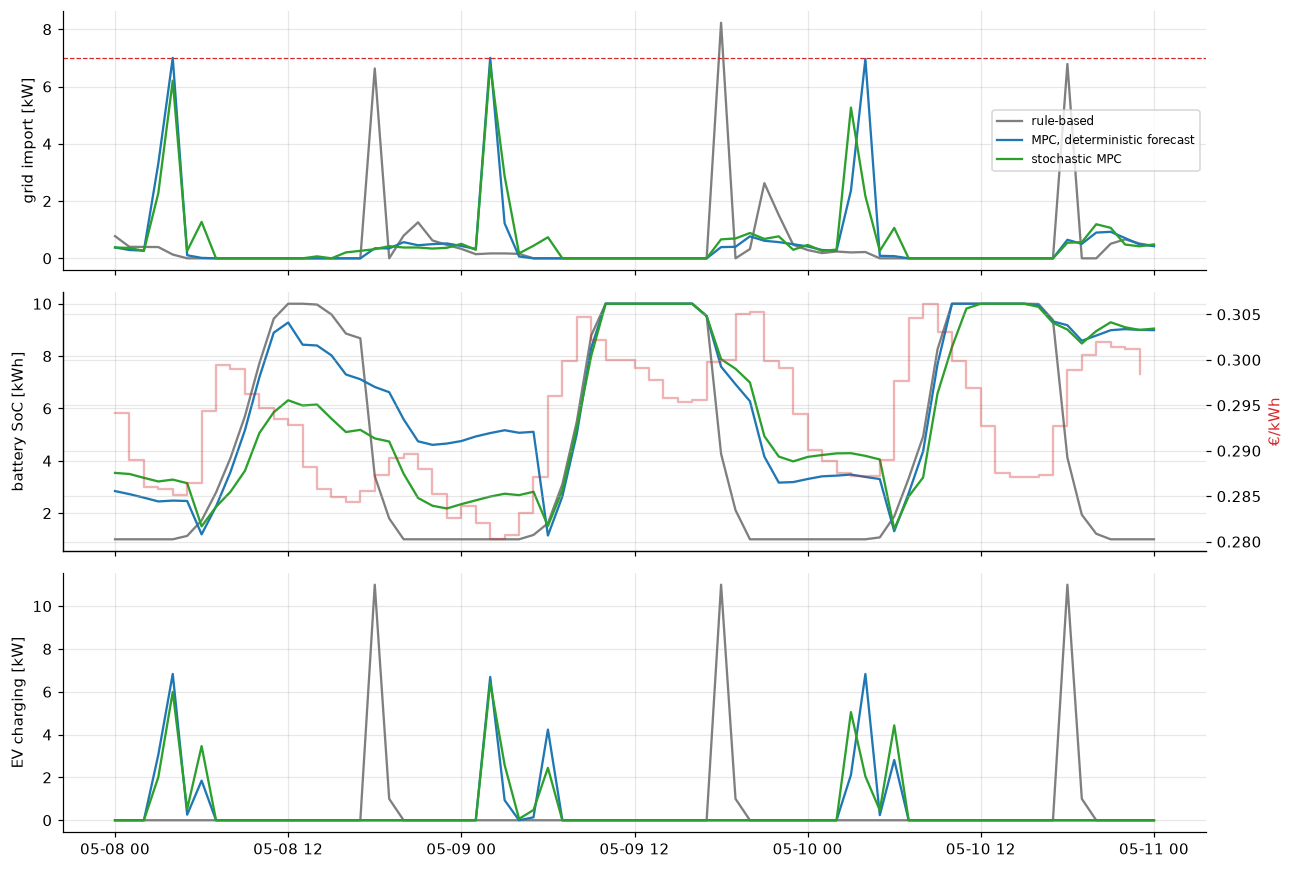

In [6]:
w = slice(hours[SIM.start + 24 * 2], hours[SIM.start + 24 * 5])
fig, ax = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for s, c in (("rule-based", "tab:grey"), ("MPC, deterministic forecast", "tab:blue"), ("stochastic MPC", "tab:green")):
    ax[0].plot(runs[s].loc[w, "import"], color=c, label=s); ax[1].plot(runs[s].loc[w, "soc"], color=c, label=s)
    ax[2].plot(runs[s].loc[w, "ev"], color=c, label=s)
ax[0].axhline(PLIM, color="tab:red", ls="--", lw=0.8); ax[0].set(ylabel="grid import [kW]"); ax[0].legend(fontsize=8)
ax1b = ax[1].twinx(); ax1b.step(hours[SIM][2 * 24:5 * 24], buy[SIM][2 * 24:5 * 24], where="post", color="tab:red", alpha=0.35); ax1b.set_ylabel("€/kWh", color="tab:red")
ax[1].set(ylabel="battery SoC [kWh]"); ax[2].set(ylabel="EV charging [kW]")
plt.tight_layout(); plt.show()

### The receding horizon in one picture
Each MPC decision comes with a 24-hour plan; only its first hour is executed. Plans made a few hours apart differ
because forecasts and the measured state changed: this is the feedback that makes MPC robust to forecast errors.

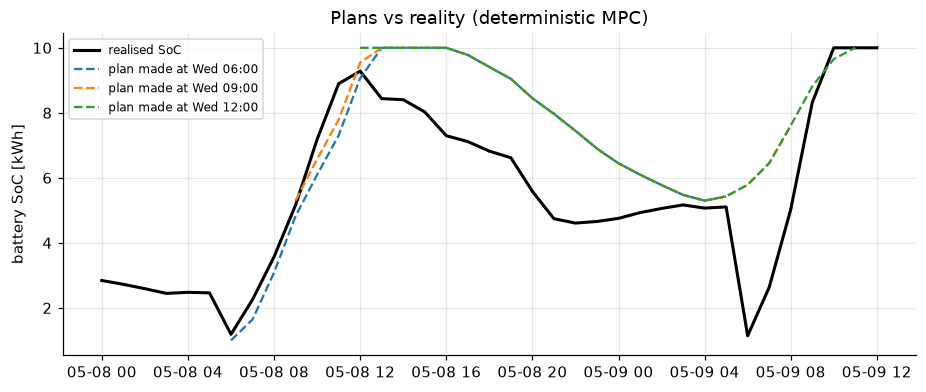

In [7]:
r = runs["MPC, deterministic forecast"]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(r.soc.loc[hours[plan_times[0] - 6]:hours[plan_times[-1] + H]], "k", lw=2, label="realised SoC")
for t0_, c in zip(plan_times, ("tab:blue", "tab:orange", "tab:green")):
    ax.plot(hours[t0_:t0_ + H], r.attrs["plans"][t0_], "--", color=c, label=f"plan made at {hours[t0_]:%a %H:%M}")
ax.set(ylabel="battery SoC [kWh]", title="Plans vs reality (deterministic MPC)"); ax.legend(fontsize=8); plt.show()

## Key takeaways
* **MPC = optimisation + forecasts + feedback.** Re-planning every hour with the measured state keeps the controller on
  track even with crude forecasts.
* Real controllers are **two-layered**: MPC plans every hour, a fast local loop absorbs the forecast error in between.
* The gap between *perfect-forecast* and *forecast-based* MPC is the **value of better forecasting** (notebooks 05–06).
* **Stochastic MPC** optimises the expected cost over error scenarios with a single first-stage decision
  (non-anticipativity); **robust MPC** protects against the worst scenario. Both are only as good as their scenarios:
  sophistication is not a free lunch, so always benchmark against simple rules.
* The same structure runs EV smart charging, heat-pump scheduling, microgrids and DSO flexibility (notebook 15).